# A/B Testing: Finding the Best Website Design
This notebook analyzes real data from an e-commerce website to determine if a newly designed product page (Version B) successfully increases sales compared to the old page (Version A). The project explores the data, displays clean visuals, and runs simple math tests to verify the findings.

In [4]:
import pandas as pd
from pandas import Series, DataFrame

# Loading our cvs file and reading it
df = pd.read_csv("/content/ab_testing_data (2).csv")
df.head()

,date,page_version,visitors,conversions,bounce_rate,avg_time_on_page
0,2025-01-01,A,902,115,55.59,79.84
1,2025-01-01,B,921,133,52.32,90.06
2,2025-01-02,A,951,106,54.44,96.93
3,2025-01-02,B,1185,169,41.08,86.24
4,2025-01-03,A,1035,115,48.00,52.33


In [5]:
# My data structure
print(df.info())
print("\n")

# Any missing values
print(df.isnull().sum())
print("\n")

# Summary of statistics
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   date              60 non-null     object 
 1   page_version      60 non-null     object 
 2   visitors          60 non-null     int64  
 3   conversions       60 non-null     int64  
 4   bounce_rate       60 non-null     float64
 5   avg_time_on_page  60 non-null     float64
dtypes: float64(2), int64(2), object(2)
memory usage: 2.9+ KB
None


date                0
page_version        0
visitors            0
conversions         0
bounce_rate         0
avg_time_on_page    0
dtype: int64


          visitors  conversions  bounce_rate  avg_time_on_page
count    60.000000    60.000000    60.000000         60.000000
mean   1009.916667   132.016667    46.838667         78.407333
std     108.444048    21.310848     6.000870         14.594773
min     801.000000    94.000000    35.660000         5

**Key findings in the data:**
There are 60 rows of data in total, representing a 30-day period with records for both Version A and Version B every single day.

**Details being tracked:**
* **date**: The day the information was collected.
* **page_version**: Whether the customer saw Version A (old design) or Version B (new design).
* **visitors**: The number of people who checked out the page that day.
* **conversions**: The number of people who actually bought something.
* **bounce_rate**: The percentage of visitors who clicked away immediately without doing anything.
* **avg_time_on_page**: How long (in seconds) visitors stayed on the page on average.

There are no missing pieces of info, meaning the dataset is clean and ready for analysis.

In [6]:
#Calculate the Conversion Rate

df["conversion_rate"] = (df["conversions"] / df["visitors"]) * 100

#Average Metrics by Page Version

avg_metrics = df.groupby("page_version").agg({
    "conversion_rate":"mean",
    "bounce_rate":"mean",
    "avg_time_on_page":"mean"
    })

print("Average Metric Results:\n")
print(avg_metrics)


Average Metric Results:

              conversion_rate  bounce_rate  avg_time_on_page
page_version                                                
A                   11.909840    49.422000         73.320000
B                   14.236749    44.255333         83.494667


## Summary of the Averages

| Feature | Version A (Old Design) | Version B (New Design) |
| :--- | :---: | :---: |
| **Conversion Rate (Sales %)** | 11.91% | 14.24% |
| **Bounce Rate (Leaving %)** | 49.42% | 44.26% |
| **Time Spent on Page** | 73.32 seconds | 83.49 seconds |

## What does this tell us?

Just by looking at the averages, Version B looks like a clear winner:
* **Sales went up** by about **2.33%**.
* **Fewer people left right away** (bounce rate dropped by **5.17%**).
* **People stayed interested longer**, spending about **10 more seconds** browsing on the new page.

These initial numbers suggest the new layout is doing a great job keeping people engaged and converting them into buyers!

# Visualizing our Data

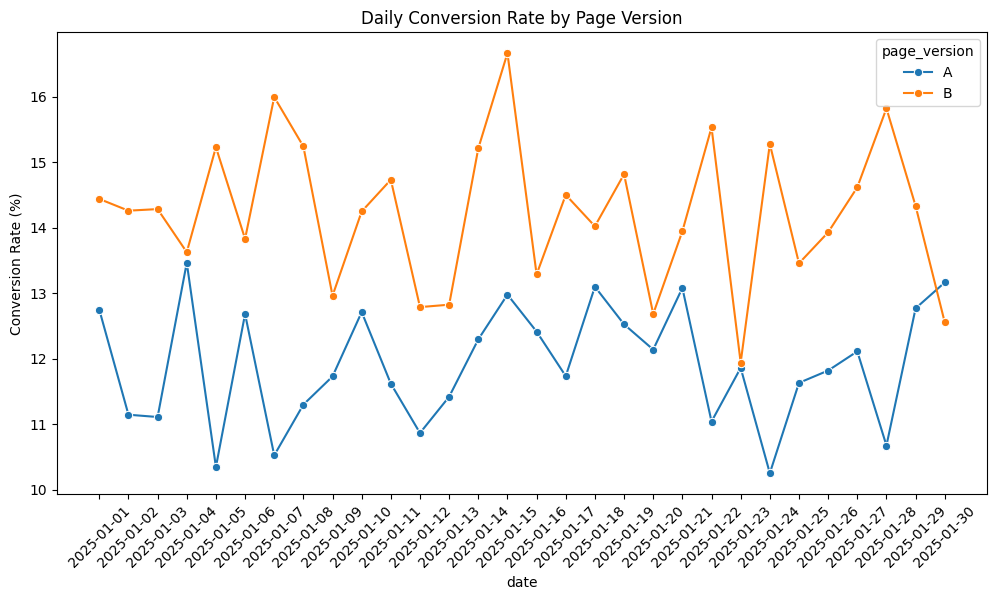

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

df["conversion_rate"] = (df["conversions"] / df["visitors"]) * 100

plt.figure(figsize=(12,6))

sns.lineplot(
    data=df,
    x="date",
    y="conversion_rate",
    hue="page_version",
    marker="o"
)

plt.xticks(rotation=45)
plt.title("Daily Conversion Rate by Page Version")
plt.ylabel("Conversion Rate (%)")
plt.show()

**Expected Insight**

The plot should show that Version B consistently trends above Version A for most days throughout the testing period.

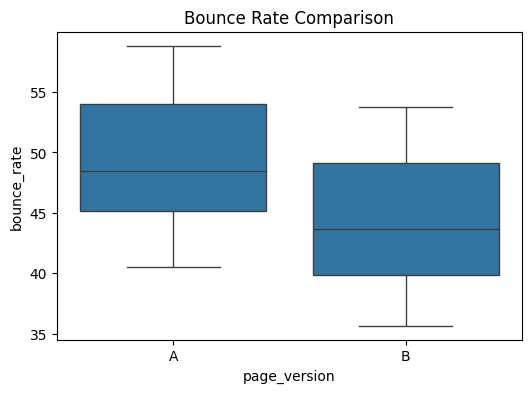

In [8]:
#Comparing our Bounce Rate
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x="page_version",
    y="bounce_rate"
)

plt.title("Bounce Rate Comparison")
plt.show()

**Expected Insight**

Version B should display a lower median bounce rate than Version A.

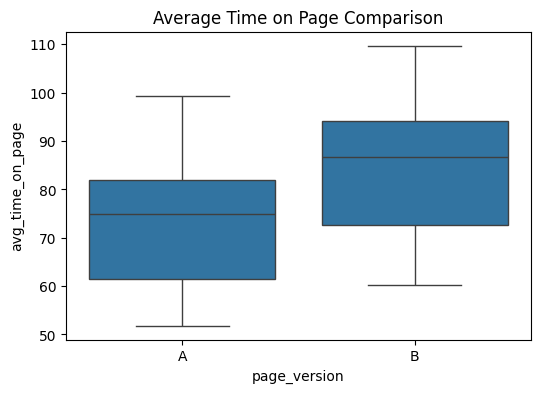

In [9]:
#Comparing the Average Time on Page
plt.figure(figsize=(6,4))

sns.boxplot(
    data=df,
    x="page_version",
    y="avg_time_on_page"
)

plt.title("Average Time on Page Comparison")
plt.show()

**Expected Insight**

Version B should show higher engagement through longer page visits.

# Conducting Statistical Analysis

In [10]:
# Step 1: Checking Normality using Shapiro_Wilk Normality Test
from scipy.stats import shapiro

# Create conversion rate
df['conversion_rate'] = (df['conversions'] / df['visitors']) * 100

# Separate groups
A = df[df['page_version'] == 'A']['conversion_rate']
B = df[df['page_version'] == 'B']['conversion_rate']

# Shapiro-Wilk Normality Test
stat_A, p_A = shapiro(A)
stat_B, p_B = shapiro(B)

print("Version A")
print("Statistic =", stat_A)
print("p-value =", p_A)

print("\nVersion B")
print("Statistic =", stat_B)
print("p-value =", p_B)

Version A
Statistic = 0.9656950861061985
p-value = 0.42900547081335827

Version B
Statistic = 0.9886216145033764
p-value = 0.9822656571573175


### Testing for a Normal "Bell Curve" Shape
Before trusting the statistical formulas, it is necessary to check if the conversion rates form a standard, symmetrical bell-shaped curve when plotted.

* **Version A**: The test score is high ($p = 0.43$), meaning it fits a normal curve nicely.
* **Version B**: The test score is also very high ($p = 0.98$), showing an almost perfect fit.

**Conclusion:** Since both scores are well above the safety threshold of 0.05, the data is distributed in a standard bell curve shape and the analysis can safely proceed.

In [11]:
# Step 2: Testing for Equal Variance using Levene's Equal Variance Test
from scipy.stats import levene

stat, p_value = levene(A, B)

print("Levene Test Statistic =", stat)
print("p-value =", p_value)
print("\n")

alpha = 0.05

if p_value > alpha:
    print("Equal variances assumed.")
else:
    print("Equal variances NOT assumed.")

Levene Test Statistic = 0.585794901479482
p-value = 0.44715319956364863


Equal variances assumed.


### Testing for Consistent Spread (Variance)
Next, it is important to make sure that the variation (the spread of the high and low points) is roughly the same for both website versions.

The test score here is **0.447**. Since this is much larger than 0.05, it indicates that the spread of data for Version A and Version B is similar enough to compare them fairly. A standard comparison test can be used with confidence.

In [12]:
# Step 3: Independent Samples t-test

from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(A, B, equal_var=True)

print("Independent Samples T-Test Results")
print("----------------------------------")
print("T-Statistic =", round(t_stat, 4))
print("P-Value =", p_value)

# Decision
alpha = 0.05

print("\nDecision:")
if p_value < alpha:
    print("Reject the null hypothesis (H0).")
    print("There is a statistically significant difference between the conversion rates of Versions A and B.")
else:
    print("Fail to reject the null hypothesis (H0).")
    print("There is no statistically significant difference between the conversion rates of Versions A and B.")

Independent Samples T-Test Results
----------------------------------
T-Statistic = -8.8169
P-Value = 2.662514447855497e-12

Decision:
Reject the null hypothesis (H0).
There is a statistically significant difference between the conversion rates of Versions A and B.


### The Comparison Test Results
This is the ultimate test to see if the differences are real or just random luck.

The final calculation gives a microscopic probability score (much less than 1 in a billion, or $p < 0.05$).

**What this means:** The chance that this improvement happened by pure coincidence is practically zero. The difference in sales between the two pages is absolutely real and highly significant.

## Final Takeaway & Recommendation

Based on math and analysis, **the new design (Version B) is a major success!** It clearly beats the old design in every single category:

1. **More Sales**: The average sales rate jumped from **11.91% to 14.24%**.
2. **Better Engagement**: Customers spent over **10 seconds longer** on the new page on average.
3. **Happier Browsers**: The percentage of people leaving immediately (bounce rate) dropped from **49.42% to 44.26%**.

Statistical checks prove that these improvements are real and not just a fluke.

**Recommendation:**
It is highly recommended that the company **permanently switch to Version B (the new page design)** as soon as possible. The design is extremely effective at catching users' attention, keeping them interested, and ultimately turning those visits into actual sales.